# Navigation without GPS: drift, a Kalman filter on a cheap chip, and the quantum accelerometer
### SymPy derivations, an op count, a C twin raced across compiler levels, and atom-interferometer phase retrieval

**In plain words.** Without GPS, a robot, drone or submarine knows where it is only by adding up
its own accelerations (dead reckoning). Every tiny sensor error grows into a large position error.
Three ways to fight back:
1. **fuse** with occasional fixes (landmarks, map matching) in a Kalman filter;
2. make the filter **learn the sensor's bias**;
3. use a **better accelerometer**. The best are quantum: clouds of cold atoms whose interference
   phase measures acceleration. Reading that phase out is a phase-retrieval problem, with the same
   ambiguities that dispersion-assisted GS solves in this repo.

The last part covers the physics and cost of hobby combat robots (antweight and beetleweight
classes).

Sensor grades are order-of-magnitude textbook classes and prices are rough planning ranges, not
specifications or quotes. Every figure uses the Okabe–Ito colorblind-safe palette, distinguishes
curves by line style as well as color, and has a printed text description.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import sympy as sp
import sys, pathlib, shutil, subprocess, os
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from dgs import gps_denied_navigation as n
sp.init_printing()
OI = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)

## 1. Why dead reckoning drifts: $t^2$ and $t^3$

An accelerometer bias $b_a$ integrates twice into a position error. A gyro bias $b_g$ tilts the
platform by an angle $b_gt$, which leaks a component $g\,b_gt$ of gravity into the horizontal
channel. SymPy solves $\ddot x=b_a+g\,b_g\,t$ from rest:

In [2]:
sp.Eq(sp.Symbol("x_err(t)"), n.drift_symbolic())

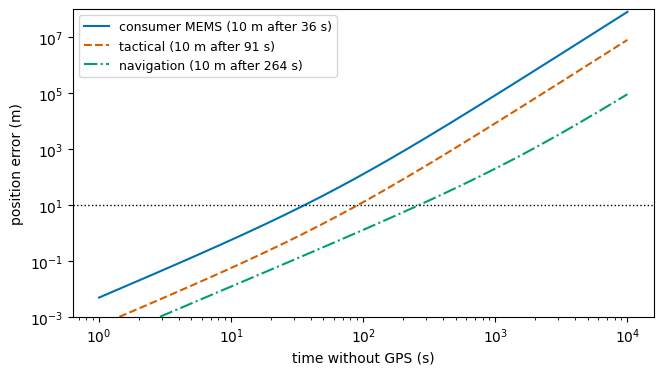

Figure description: position error versus time on log axes for three sensor grades. Each curve bends from slope 2 (accelerometer bias) to slope 3 (gyro tilt). Consumer MEMS (solid) reaches 10 m in about half a minute, tactical (dashed) in about 1.5 min, navigation grade (dash-dot) in about 4.4 min.


In [3]:
t = np.logspace(0, 4, 300)
fig, ax = plt.subplots(figsize=(7.5, 4))
for (name, (ba, bg)), ls in zip(n.SENSOR_GRADES.items(), ["-", "--", "-."]):
    ax.loglog(t, n.drift_error(t, ba, bg), ls=ls, label=f"{name} (10 m after {n.time_to_error(10, ba, bg):.0f} s)")
ax.axhline(10, c="k", ls=":", lw=1); ax.set_xlabel("time without GPS (s)"); ax.set_ylabel("position error (m)")
ax.legend(fontsize=9); ax.set_ylim(1e-3, 1e8); plt.show()
print("Figure description: position error versus time on log axes for three sensor grades. Each curve bends "
      "from slope 2 (accelerometer bias) to slope 3 (gyro tilt). Consumer MEMS (solid) reaches 10 m in about "
      "half a minute, tactical (dashed) in about 1.5 min, navigation grade (dash-dot) in about 4.4 min.")

## 2. The fix: a Kalman filter, and what it costs in $\times\div+-$

The filter predicts with the accelerometer and corrects with a position fix (a landmark, or a
match against a terrain or gravity map) every 30 s. There are two versions:
* **2-state** $(x,v)$: corrects position, but the bias keeps pushing the estimate between fixes;
* **3-state** $(x,v,b)$: also **estimates the bias**, so drift between fixes nearly vanishes.

SymPy builds both symbolically and counts the arithmetic operations. With **common-subexpression
elimination (CSE)**, every repeated product is computed once, which is what an optimizing compiler
does.

In [4]:
for ns_ in (2, 3):
    b = n.kalman_op_budget(ns_)
    print(f"{ns_}-state: predict {b['predict_naive']:4d} -> {b['predict_cse']:3d} ops (CSE);  "
          f"predict+update {b['update_naive']:4d} -> {b['update_cse']:3d} ops (CSE)")
b3 = n.kalman_op_budget(3)["update_cse"]
for rate in (100, 1000):
    print(f"3-state at {rate:5d} Hz on an assumed 10 MFLOP/s microcontroller: {100*n.mcu_load(b3, rate):.2f}% load")

2-state: predict   27 ->  24 ops (CSE);  predict+update  153 ->  39 ops (CSE)
3-state: predict   79 ->  47 ops (CSE);  predict+update  596 ->  79 ops (CSE)
3-state at   100 Hz on an assumed 10 MFLOP/s microcontroller: 0.08% load
3-state at  1000 Hz on an assumed 10 MFLOP/s microcontroller: 0.79% load


The naive 3-state update is 596 operations; CSE brings it to 79, a 7.5× reduction. At
1 kHz that's under 1% of a small floating-point microcontroller. Arithmetic isn't the
bottleneck; sensor quality is.

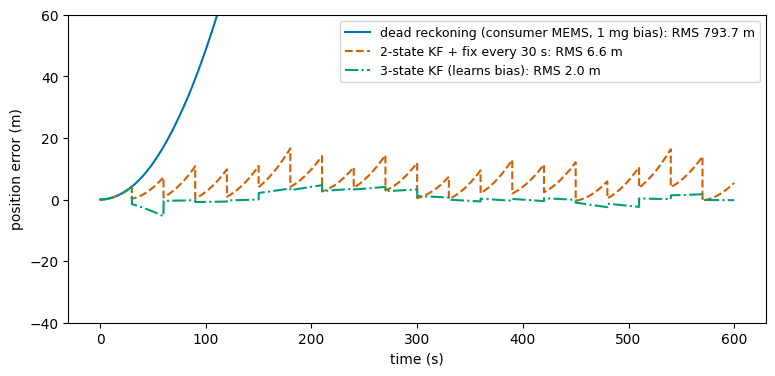

bias learned by 3-state filter: 9.7889 mm/s^2  (true 9.8066)
Figure description: dead-reckoning error (solid) climbs off the top of the plot, reaching about 1.8 km at 600 s. The 2-state filter (dashed) shows a sawtooth of tens of meters between fixes. The 3-state filter (dash-dot) stays within a few meters after the first fix.


In [5]:
r = n.simulate_navigation()
fig, ax = plt.subplots(figsize=(9, 4))
for key, ls, lab in (("dead_reckoning", "-", "dead reckoning (consumer MEMS, 1 mg bias)"),
                     ("kf2", "--", "2-state KF + fix every 30 s"), ("kf3", "-.", "3-state KF (learns bias)")):
    e = r[key] - r["truth"]
    ax.plot(r["t"], e, ls=ls, label=f"{lab}: RMS {np.sqrt(np.mean(e**2)):.1f} m")
ax.set_ylim(-40, 60); ax.set_xlabel("time (s)"); ax.set_ylabel("position error (m)"); ax.legend(fontsize=9); plt.show()
print(f"bias learned by 3-state filter: {r['bias_estimate']*1e3:.4f} mm/s^2  (true {r['bias_true']*1e3:.4f})")
print("Figure description: dead-reckoning error (solid) climbs off the top of the plot, reaching about 1.8 km "
      "at 600 s. The 2-state filter (dashed) shows a sawtooth of tens of meters between fixes. The 3-state "
      "filter (dash-dot) stays within a few meters after the first fix.")

## 3. The compiler race: same math, C, five optimization levels

`learn/gps_denied_nav/kf3.c` is the 3-state filter written out by hand with shared
subexpressions, with no matrix library: the version you would put on a microcontroller. It was
checked line by line against the Python filter (agreement to $4\times10^{-16}$). Below it is
compiled with gcc at `-O0 … -Ofast` and timed over 20 million steps. The checksum (final state)
must be **identical** at every level; otherwise an optimization changed the answer.

In [6]:
gcc = shutil.which("gcc") or (r"C:\msys64\mingw64\bin\gcc.exe" if os.path.exists(r"C:\msys64\mingw64\bin\gcc.exe") else None)
src = pathlib.Path.cwd().parent / "learn" / "gps_denied_nav" / "kf3.c"
results = {}
if gcc is None:
    print("gcc not found -- skipping the race (install MSYS2 MinGW to run it)")
else:
    env = dict(os.environ, PATH=str(pathlib.Path(gcc).parent) + os.pathsep + os.environ.get("PATH", ""))
    build = pathlib.Path(os.environ.get("TEMP", "/tmp")) / "kf3_race"; build.mkdir(exist_ok=True)
    for opt in ("-O0", "-O1", "-O2", "-O3", "-Ofast"):
        exe = build / f"kf3{opt}.exe"
        subprocess.run([gcc, "-std=c99", "-Wall", "-Wextra", opt, str(src), "-o", str(exe)], check=True, env=env)
        out = subprocess.run([str(exe), "20000000"], capture_output=True, text=True, env=env).stdout.strip()
        ns_step = float(out.split("ns/step=")[1].split()[0]); chk = out.split("bias_est=")[1]
        results[opt] = (ns_step, chk); print(f"{opt:6s} {ns_step:6.2f} ns/step   checksum {chk}")
    print("identical checksums:", len({c for _, c in results.values()}) == 1)

-O0     12.15 ns/step   checksum 0.009760152  x=0.761334049  v=0.000510866


-O1      4.25 ns/step   checksum 0.009760152  x=0.761334049  v=0.000510866


-O2      3.55 ns/step   checksum 0.009760152  x=0.761334049  v=0.000510866


-O3      3.65 ns/step   checksum 0.009760152  x=0.761334049  v=0.000510866


-Ofast   3.60 ns/step   checksum 0.009760152  x=0.761334049  v=0.000510866
identical checksums: True


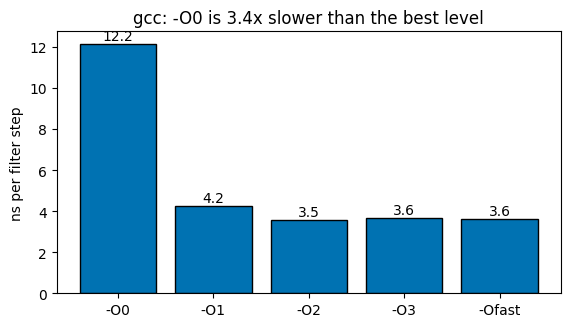

Figure description: bar chart of nanoseconds per Kalman step for each gcc optimization level; -O0 is the tallest bar, and -O1 through -Ofast are all several times faster and close to each other.


In [7]:
if results:
    opts = list(results); ns_ = [results[o][0] for o in opts]
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    bars = ax.bar(opts, ns_, color=OI[0], edgecolor="black")
    for b_, v in zip(bars, ns_): ax.text(b_.get_x() + b_.get_width()/2, v + 0.2, f"{v:.1f}", ha="center")
    ax.set_ylabel("ns per filter step"); ax.set_title(f"gcc: -O0 is {ns_[0]/min(ns_):.1f}x slower than the best level"); plt.show()
    print("Figure description: bar chart of nanoseconds per Kalman step for each gcc optimization level; "
          "-O0 is the tallest bar, and -O1 through -Ofast are all several times faster and close to each other.")

Most of the speedup arrives at `-O1`, when values stay in registers instead of memory.
After that the gains are small. `-Ofast` permits floating-point reordering that *could* change
results. Here the checksums still match, but that's not guaranteed in general. Navigation code
usually ships at `-O2` and keeps strict IEEE floating-point semantics.

*Timings are for this PC's x86 CPU. A microcontroller is about 100× slower per step and still
easily fast enough, as §2 shows.*

## 4. The quantum accelerometer

A light-pulse **atom interferometer** splits a cloud of cold rubidium atoms with laser pulses at
$0$, $T$ and $2T$. The phase difference between the two paths depends only on the acceleration:

In [8]:
sp.Eq(sp.Symbol("phi"), n.ai_phase_symbolic())

In [9]:
print(f"k_eff (Rb, 780 nm) = {n.k_eff():.4e} rad/m")
for T in (0.005, 0.01, 0.05):
    s = n.ai_shot_noise_sensitivity(T, 1e6)
    print(f"T = {T*1e3:4.0f} ms, 1e6 atoms, C=0.5:  {s:.2e} m/s^2 per shot = {s/n.MG*1e3:7.3f} micro-g")
print(f"\ncompare: navigation-grade accelerometer bias ~ {n.SENSOR_GRADES['navigation'][0]/n.MG*1e3:.0f} micro-g")

k_eff (Rb, 780 nm) = 1.6106e+07 rad/m
T =    5 ms, 1e6 atoms, C=0.5:  4.97e-06 m/s^2 per shot =   0.507 micro-g
T =   10 ms, 1e6 atoms, C=0.5:  1.24e-06 m/s^2 per shot =   0.127 micro-g
T =   50 ms, 1e6 atoms, C=0.5:  4.97e-08 m/s^2 per shot =   0.005 micro-g

compare: navigation-grade accelerometer bias ~ 25 micro-g


Sensitivity scales as $T^2$, so longer free-fall time gives a much better sensor. That's why
the best atom gravimeters are tall towers, and why shrinking them for vehicles is hard
engineering.

### Reading it out is phase retrieval

The detector counts atoms in the excited state: $P=\tfrac12(1-C\cos(k_{\text{eff}}aT^2+\phi_L))$.
That's an **intensity**, so the phase is hidden, with two ambiguities:
* **$2\pi$ comb:** $\cos$ repeats, so many accelerations give the same fringe;
* **twin sign:** $\cos$ is even, so $+a$ and $-a$ look identical. This is the twin-image ambiguity of Gerchberg–Saxton.

The fixes mirror dispersion-assisted GS. A **second interrogation time** works like a second
dispersion $D_2$. A **π/2 laser phase step** $\phi_L$ works like a quadrature measurement.

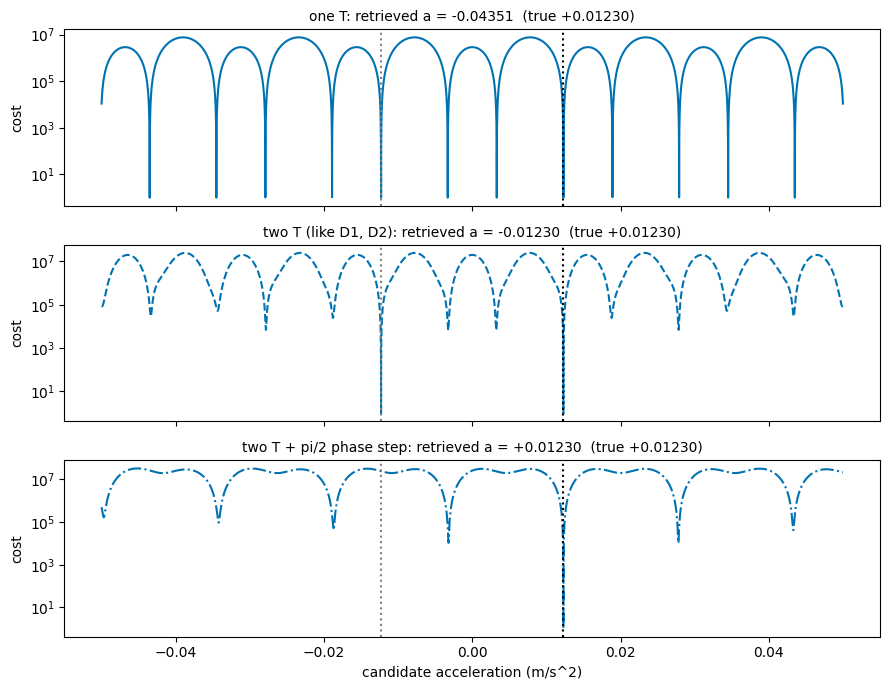

Figure description: three stacked cost curves over candidate accelerations. Top: many equally deep minima (the 2 pi comb). Middle: one minimum survives at +a and a mirror-image twin at -a. Bottom: a single deep minimum at the true value. Dotted lines mark +a (black) and -a (gray).


In [10]:
a_true = 0.0123
grid = np.linspace(-0.05, 0.05, 200001)
cases = {"one T": [(0.005, 0)], "two T (like D1, D2)": [(0.005, 0), (0.0071, 0)],
         "two T + pi/2 phase step": [(0.005, 0), (0.005, np.pi/2), (0.0071, 0), (0.0071, np.pi/2)]}
fig, axs = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
for ax, (name, st), ls in zip(axs, cases.items(), ["-", "--", "-."]):
    ms = [n.ai_measure(a_true, T, 1e6, phase_offset=ph, n_shots=20, rng=i) for i, (T, ph) in enumerate(st)]
    best, cost = n.ai_retrieve(ms, st, grid, 1e6)
    ax.semilogy(grid, cost - cost.min() + 1, ls=ls)
    ax.axvline(a_true, c="k", ls=":"); ax.axvline(-a_true, c="0.5", ls=":")
    ax.set_title(f"{name}: retrieved a = {best:+.5f}  (true {a_true:+.5f})", fontsize=10)
    ax.set_ylabel("cost")
axs[-1].set_xlabel("candidate acceleration (m/s^2)"); plt.tight_layout(); plt.show()
print("Figure description: three stacked cost curves over candidate accelerations. Top: many equally deep minima "
      "(the 2 pi comb). Middle: one minimum survives at +a and a mirror-image twin at -a. Bottom: a single deep "
      "minimum at the true value. Dotted lines mark +a (black) and -a (gray).")

## 5. Quantum vs classical drift

If the quantum sensor's resolution is used to keep calibrating the accelerometer bias, the
remaining position error grows as a random walk, $\sigma_x\propto t^{3/2}$, instead of as
$t^2$ from an uncorrected bias. The gyro still matters, and quantum gyroscopes are a separate,
harder problem.

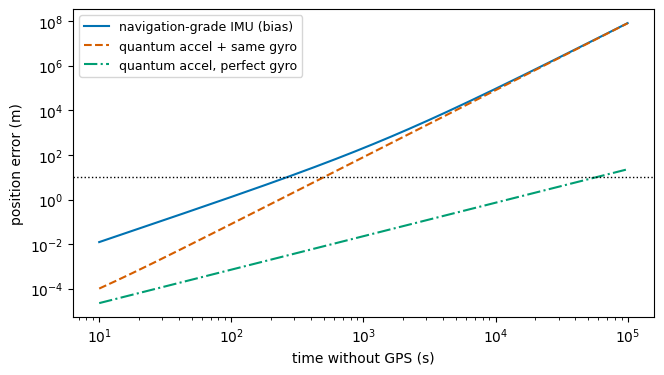

Figure description: navigation-grade IMU drift (solid) versus a quantum accelerometer paired with the same gyro (dashed) and with a perfect gyro (dash-dot). The quantum accelerometer delays the 10 m crossing; at long times the gyro's t^3 term dominates the dashed curve.


In [11]:
t = np.logspace(1, 5, 300)
s = n.ai_shot_noise_sensitivity(0.01, 1e6)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.loglog(t, n.drift_error(t, *n.SENSOR_GRADES["navigation"]), "-", label="navigation-grade IMU (bias)")
ax.loglog(t, n.drift_with_quantum_accel(t, s, 1.0, n.SENSOR_GRADES["navigation"][1]), "--", label="quantum accel + same gyro")
ax.loglog(t, n.drift_with_quantum_accel(t, s, 1.0, 0.0), "-.", label="quantum accel, perfect gyro")
ax.axhline(10, c="k", ls=":", lw=1); ax.set_xlabel("time without GPS (s)"); ax.set_ylabel("position error (m)"); ax.legend(fontsize=9); plt.show()
print("Figure description: navigation-grade IMU drift (solid) versus a quantum accelerometer paired with the same "
      "gyro (dashed) and with a perfect gyro (dash-dot). The quantum accelerometer delays the 10 m crossing; at long "
      "times the gyro's t^3 term dominates the dashed curve.")

Reading the 10 m crossings off these curves: about **264 s** for the navigation-grade inertial
unit, about **500 s** for the quantum accelerometer with the same gyro, and about **58,000 s (16 h)**
with a perfect gyro.

The gyro sets the ceiling. That's why research programs pursue quantum accelerometers and
quantum gyroscopes together, and why map matching (terrain, magnetic or gravity anomalies) is
still needed for very long missions.

## 6. Hobby combat robotics: the physics and the bill

In robot-combat competitions, the arena rules cap weight. The common entry classes are
**antweight (1 lb, 454 g)** and **beetleweight (3 lb, 1.36 kg)**. A spinning-disk weapon stores
$E=\tfrac12I\omega^2$ with $I=\tfrac12mr^2$:

In [12]:
for m_, r_, rpm in [(0.10, 0.04, 12000), (0.15, 0.05, 10000), (0.40, 0.08, 8000)]:
    E = n.disk_spinner_energy(m_, r_, rpm)
    print(f"disk {m_*1e3:4.0f} g, r = {r_*100:3.0f} cm, {rpm:5d} rpm:  E = {E:6.1f} J   spin-up with 100 W motor: {n.spinup_time(m_, r_, rpm, 100):.2f} s")

disk  100 g, r =   4 cm, 12000 rpm:  E =   63.2 J   spin-up with 100 W motor: 1.05 s
disk  150 g, r =   5 cm, 10000 rpm:  E =  102.8 J   spin-up with 100 W motor: 1.71 s
disk  400 g, r =   8 cm,  8000 rpm:  E =  449.2 J   spin-up with 100 W motor: 7.49 s


Energy grows as $r^2\omega^2$, so a slightly larger disk or faster motor stores a lot more.
That's why arenas have polycarbonate walls and events require weapon locks and a
safety check before every fight.

**Rough first-build budget** (planning ranges only; prices vary widely, so get real quotes):

In [13]:
for cls, items in n.COMBAT_ROBOT_BUDGET_USD.items():
    lo, hi = n.budget_range(cls)
    print(f"{cls}: about ${lo}-{hi}")
    for k, (a, b) in items.items():
        print(f"    {k:34s} ${a}-{b}")
print("\nNot included: tools (soldering iron, 3D printer access), spare parts, event entry fees, travel.")

antweight (1 lb / 454 g): about $130-410
    drive motors + ESCs                $40-120
    weapon motor + ESC                 $20-60
    battery + charger                  $30-80
    radio tx/rx                        $30-100
    chassis material / 3D print        $10-50
beetleweight (3 lb / 1.36 kg): about $210-770
    drive motors + ESCs                $60-200
    weapon motor + ESC                 $40-150
    battery + charger                  $40-120
    radio tx/rx                        $30-100
    chassis (UHMW / aluminum / TPU)    $40-200

Not included: tools (soldering iron, 3D printer access), spare parts, event entry fees, travel.


## 7. Summary

| idea | number from this notebook |
|---|---|
| consumer MEMS → 10 m error | about 36 s without GPS |
| 3-state KF, fixes every 30 s | RMS error ≈ 2 m (vs 1.8 km dead reckoning) |
| ops per 3-state update | 596 naive → 79 with CSE (< 1% of a small MCU at 1 kHz) |
| gcc -O0 vs best level | about 3× faster, identical answer |
| atom interferometer, T = 10 ms | ≈ 0.13 µg per shot |
| quantum readout ambiguity | broken by two T's (like D₁, D₂) plus a π/2 phase step |

**Connections to the rest of the repo:**
* The Kalman filter is the same linear-algebra machine as `dgs.markov` and `dgs.cell_hilbert_bridge`: a state vector propagated by a matrix.
* The op-count and critical-path thinking is `dgs.logic_timing`.
* Breaking the atom-interferometer ambiguity is `dgs.gs_core` with laser pulses instead of fiber.

*Synthetic data; civilian education. Sensor grades are generic classes, not products.*